# Part 2: Fine-Tuning Stable Diffusion 1.5

In [1]:
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '47d014c', 'python': '3.11.18', 'torch': '2.15.0', 'gpu': 'cpu', 'seed': 266}


## Setup

In [2]:
import io, json, hashlib, collections
from pathlib import Path
from PIL import Image
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
PART = Path.cwd().parent
DATA = PART / "data"
EVAL = PART.parents[1] / "eval"

## 1. Data preparation

### 1.1 Load the Pokemon dataset

In [3]:
from datasets import load_dataset, Image as HFImage

ds = load_dataset("reach-vb/pokemon-blip-captions", split="train").cast_column("image", HFImage(decode=False))
print(ds)
print("rows before cleaning:", len(ds))

Dataset({
    features: ['image', 'text'],
    num_rows: 833
})
rows before cleaning: 833


### 1.2 Remove corrupted and duplicate images

In [4]:
def open_image(data):
    Image.open(io.BytesIO(data)).verify()
    img = Image.open(io.BytesIO(data))
    img.load()
    return img.convert("RGB")


def thumb(img):
    return np.asarray(img.resize((16, 16), Image.BILINEAR), dtype=np.float32)


def ahash(t):
    return (t > t.mean()).flatten()


copy_bits, copy_diff = [], []
for i in random.Random(SEED).sample(range(len(ds)), 40):
    img = open_image(ds[i]["image"]["bytes"])
    buf = io.BytesIO()
    img.resize((img.width * 3 // 4, img.height * 3 // 4)).save(buf, "JPEG", quality=75)
    a, b = thumb(img), thumb(open_image(buf.getvalue()))
    copy_bits.append(int((ahash(a) != ahash(b)).sum()))
    copy_diff.append(float(np.abs(a - b).mean()))
print("re-saved copies (75% size, JPEG 75): max hash bits", max(copy_bits), "| max color diff", round(max(copy_diff), 2))

re-saved copies (75% size, JPEG 75): max hash bits 9 | max color diff 0.33


In [5]:
MAX_BITS, MAX_DIFF = 10, 2.0
print(f"near duplicate = at most {MAX_BITS} of 768 hash bits differ and mean 16x16 color difference at most {MAX_DIFF} (same layout and same colors)")

corrupted, exact, near, keep, closest = [], [], [], [], []
seen, kept_hash, kept_thumb, sizes, white = {}, [], [], {}, {}
for i in range(len(ds)):
    try:
        img = open_image(ds[i]["image"]["bytes"])
    except Exception:
        corrupted.append(i)
        continue
    key = hashlib.md5(img.tobytes()).hexdigest() + str(img.size)
    if key in seen:
        exact.append((seen[key], i))
        continue
    seen[key] = i
    t = thumb(img)
    h = ahash(t)
    if keep:
        bits = (np.array(kept_hash) != h).sum(1)
        diff = np.abs(np.array(kept_thumb) - t).mean(axis=(1, 2, 3))
        match = np.flatnonzero((bits <= MAX_BITS) & (diff <= MAX_DIFF))
        if len(match):
            near.append((keep[match[0]], i))
            continue
        j = int(bits.argmin())
        closest.append((int(bits[j]), round(float(diff[j]), 2), keep[j], i))
    keep.append(i)
    kept_hash.append(h)
    kept_thumb.append(t)
    sizes[i] = img.size
    white[i] = min(img.getpixel((2, 2))) >= 240

print("corrupted:", len(corrupted))
print("exact duplicates:", len(exact))
print("near duplicates:", len(near))
print("rows after cleaning:", len(keep))

near duplicate = at most 10 of 768 hash bits differ and mean 16x16 color difference at most 2.0 (same layout and same colors)


corrupted: 0
exact duplicates: 0
near duplicates: 0
rows after cleaning: 833


near-duplicate pairs removed: []
closest kept pair 715 and 718: 8 bits, color diff 14.56 | a green butterfly with red and black wings | a green and brown butterfly on a white background
closest kept pair 605 and 606: 12 bits, color diff 3.17 | a drawing of a deer with a bow on its head | a pink and yellow deer with a yellow bow on its head
closest kept pair 606 and 608: 15 bits, color diff 3.31 | a pink and yellow deer with a yellow bow on its head | a cartoon deer with a yellow bow on its head


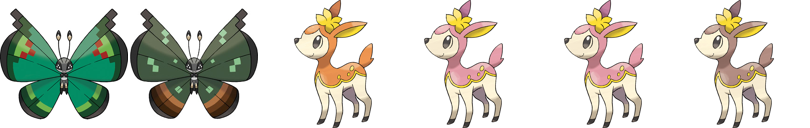

In [6]:
def show_pairs(pairs):
    sheet = Image.new("RGB", (len(pairs) * 270, 128), "white")
    for k, (a, b) in enumerate(pairs):
        for r, i in enumerate((a, b)):
            sheet.paste(open_image(ds[i]["image"]["bytes"]).resize((128, 128)), (k * 270 + r * 130, 0))
    return sheet


print("near-duplicate pairs removed:", near[:3])
top = sorted(closest)[:3]
for bits, diff, a, b in top:
    print(f"closest kept pair {a} and {b}: {bits} bits, color diff {diff} | {ds[a]['text']} | {ds[b]['text']}")
display(show_pairs(near[:3] if near else [(a, b) for _, _, a, b in top]))

### 1.3 Train and test split (90/10, seed 266)

In [7]:
def split(ids, seed=SEED, test_frac=0.1):
    ids = sorted(ids)
    random.Random(seed).shuffle(ids)
    n_test = round(len(ids) * test_frac)
    return sorted(ids[n_test:]), sorted(ids[:n_test])


train_ids, test_ids = split(keep)
print("train:", len(train_ids), "| test:", len(test_ids))
print("same test ids on a second run:", split(keep)[1] == test_ids)
print("train and test overlap:", len(set(train_ids) & set(test_ids)))
print("first 10 test ids:", test_ids[:10])

train: 750 | test: 83
same test ids on a second run: True
train and test overlap: 0
first 10 test ids: [3, 9, 14, 19, 22, 23, 25, 35, 44, 53]


### 1.4 Resize to 512x512

In [8]:
def to_512(img):
    s = min(img.size)
    left, top = (img.width - s) // 2, (img.height - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((512, 512), Image.LANCZOS)


print("non-square images (center cropped):", sum(w != h for w, h in (sizes[i] for i in keep)))
for name, ids in [("train", train_ids), ("test", test_ids)]:
    out = DATA / name
    out.mkdir(parents=True, exist_ok=True)
    with open(out / "metadata.jsonl", "w") as f:
        for i in ids:
            file_name = f"{i:04d}.png"
            to_512(open_image(ds[i]["image"]["bytes"])).save(out / file_name)
            f.write(json.dumps({"file_name": file_name, "text": ds[i]["text"]}) + "\n")
    print(name, len(list(out.glob("*.png"))), "images saved in", out.relative_to(PART))

train_check = load_dataset("imagefolder", data_files={"train": str(DATA / "train" / "**")}, split="train")
print("loads like the diffusers script:", train_check.column_names, len(train_check), train_check[0]["image"].size)
print(subprocess.run(["git", "check-ignore", "-v", str(DATA / "train" / "metadata.jsonl")], capture_output=True, text=True).stdout.strip())

non-square images (center cropped): 0


train 750 images saved in data/train


test 83 images saved in data/test


loads like the diffusers script: ['image', 'text'] 750 (512, 512)
.gitignore:8:data/	/Users/manavnayanbhaipatel/Desktop/SJSU/DATA - 266/LAB - 2/Data266-Lab2-Team17/part2_diffusion/member_manav/data/train/metadata.jsonl


### 1.5 Dataset description, limitations and biases

In [9]:
caps = [ds[i]["text"] for i in keep]
words = [len(c.split()) for c in caps]
print("caption words: min", min(words), "| median", int(np.median(words)), "| max", max(words))
print("most common caption starts:", collections.Counter(" ".join(c.split()[:3]) for c in caps).most_common(5))
print("captions with the word pokemon:", sum("pokemon" in c.lower() for c in caps))
print("captions with 'white background':", sum("white background" in c for c in caps))
print("images with a white top-left corner:", sum(white[i] for i in keep), "of", len(keep))
print("source sizes:", collections.Counter(sizes[i] for i in keep).most_common(4))
print("images smaller than 512 px (upscaled):", sum(min(sizes[i]) < 512 for i in keep))

caption words: min 6 | median 9 | max 16
most common caption starts: [('a drawing of', 312), ('a cartoon character', 89), ('a very cute', 51), ('a blue and', 41), ('a picture of', 24)]
captions with the word pokemon: 116
captions with 'white background': 17
images with a white top-left corner: 833 of 833
source sizes: [((1280, 1280), 453), ((431, 431), 258), ((1080, 1080), 27), ((272, 272), 12)]
images smaller than 512 px (upscaled): 279


**Dataset.** Pokemon BLIP Captions (`reach-vb/pokemon-blip-captions`, a copy of the Lambda Labs set). Each row is one Pokemon picture with one short caption written by the BLIP captioning model. All counts are printed by the cells above.

**Limitation 1: caption style.** The captions come from BLIP, not from people. They are short and generic: many start with "a drawing of" or "a cartoon character", most never say "pokemon" or the creature's name, and some are wrong (one butterfly is "made out of paper"). The model learns this vague style, so prompts written like real descriptions may match it less well.

**Limitation 2: one look, with repeats.** Every image is a single creature on a plain white background in the same official art style, but very few captions mention the background. The model will likely add white backgrounds everywhere. Some creatures appear several times in different colors (the deer and butterfly forms shown above), and many small images are upscaled to 512x512, so they are softer.

**License.** CC BY-NC-SA 4.0, checked on the dataset card on 2026-11-02. The characters are copyrighted, so this data and the models trained on it are for non-commercial research only.

## 2. Fine-tuning

### 2.1 Run 1: LoRA rank 8

### 2.2 Run 2: LoRA rank 32

### 2.3 Training table

### 2.4 Push both models to Hugging Face

## 3. Image generation

### 3.1 The 20 fixed prompts

In [10]:
eligible = [i for i in test_ids if len(ds[i]["text"].split()) >= 4]
picked = sorted(random.Random(SEED).sample(eligible, 10))
prompts = [{"id": f"P{k:02d}", "type": "in-domain", "prompt": ds[i]["text"], "test_image_id": i} for k, i in enumerate(picked, 1)]

path = EVAL / "p2_prompts_manav.json"
if not path.exists():
    path.write_text(json.dumps(prompts, indent=2) + "\n")
print("eligible test captions:", len(eligible))
print("prompts file matches this draw:", json.loads(path.read_text()) == prompts)
for p in prompts:
    print(p["id"], p["test_image_id"], p["prompt"])

eligible test captions: 83
prompts file matches this draw: True
P01 35 a red fish with a gold crown on its head
P02 44 a very cute looking pokemon with big eyes
P03 97 a bird with a long beak flying through the air
P04 100 a yellow and white cartoon character with a red eye
P05 255 a drawing of a dragon with black and white spots
P06 491 a robot with a yellow helmet and green legs
P07 547 a cartoon character holding a large piece of wood
P08 575 a cartoon picture of a giant spider crawling out of a rock
P09 679 a very cute looking cartoon character with big eyes
P10 690 a drawing of a cartoon character with long hair


### 3.2 Generate with base, run 1 and run 2 (seeds 0 and 1)

### 3.3 Side-by-side grids for 8 prompts

### 3.4 Upload images to a Hugging Face dataset

## 4. Evaluation

### 4.1 Primary: KID and CLIP score

### 4.2 Secondary: LPIPS diversity

### 4.3 Human evaluation: blinded pairs

### 4.4 Efficiency: GPU-hours and peak memory

### 4.5 Results table

### 4.6 Failure modes and choice of run

## 5. Safety

### 5.1 License

### 5.2 NSFW filter

### 5.3 Memorization check

## 6. Model card